# Baltimore 311 Resolution Time: Tree Models (Part 3)

**Team Chingu:** Manikrishneshwar Sasidhar, Yeo Eun Yoon

Part 2 fit a linear regression on 2024 and scored it on 2025. Its conclusion was that almost all of
the fit is the request-type indicators, and that the model lands close to simply predicting each
request type's median. Two things it could not do were use the predictors whose relationship with
resolution time is not additive, and use location, which it left out because neighborhood explains
little of the log-time variation *in a straight additive sense*.

This notebook fits the two tree models that can do both:

1. **Random forest** — many deep trees on bootstrap samples, averaged.
2. **Gradient boosting** (LightGBM) — shallow trees fit in sequence on the running residual.

Both are run on two feature sets: the exact set part 2 used, and an expanded set that adds agency,
intake method, neighborhood, council district and coordinates. Comparing those two answers a
question part 2 had to leave open: **does location matter once a model can use it non-additively?**

Everything else is held identical to part 2 — same rows, same 2024/2025 split, same `log1p` target,
same metrics — so the numbers drop straight into one comparison table.

## 0. Setup

In [1]:
import time
import warnings
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
import statsmodels.api as sm
from IPython.display import display
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED_DIR = ROOT / "data" / "processed"
FIG_DIR = ROOT / "figures"
RESULTS_DIR = ROOT / "results"
FIG_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Held identical to part 2.
SLA_MAX = 120
MIN_TYPE_N = 200
SEED = 311

# New in this notebook: the last quarter of 2024 is the validation set.
VALID_START_MONTH = 10
RF_TUNE_N = 150_000

MONTH_NAMES = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]


def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()


def metrics(days_true, log_true, log_pred):
    # Part 2's metrics: MAE/RMSE/R2 in days (via expm1), plus R2 on the log scale.
    days_true = np.asarray(days_true, dtype=float)
    log_true = np.asarray(log_true, dtype=float)
    days_pred = np.expm1(log_pred)
    e_days = days_true - days_pred
    e_log = log_true - log_pred
    return {
        "MAE": np.mean(np.abs(e_days)),
        "RMSE": np.sqrt(np.mean(e_days ** 2)),
        "R2": 1 - (e_days ** 2).sum() / ((days_true - days_true.mean()) ** 2).sum(),
        "R2_log": 1 - (e_log ** 2).sum() / ((log_true - log_true.mean()) ** 2).sum(),
    }

/Users/yun-yeoeun/Library/Python/3.11/lib/python/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load the cleaned data and reproduce part 2's rows

Same file and same deadline filter as part 2: `sla_days` from 0 through 120 days. The asserts are
there so this notebook fails loudly if the cleaning output ever changes underneath it.

In [2]:
df = pd.read_parquet(PROCESSED_DIR / "311_clean_2024_2025.parquet")
n_clean = len(df)
df = df[df["sla_days"].between(0, SLA_MAX)].copy()

# Request types rarer than MIN_TYPE_N in the 2024 training year collapse into "Other",
# exactly as in part 2. The vocabulary comes from the training year only.
is_2024 = df["source_year"] == 2024
type_counts = df.loc[is_2024, "SRType"].value_counts()
common_types = set(type_counts[type_counts >= MIN_TYPE_N].index)
df["request_type"] = np.where(df["SRType"].isin(common_types), df["SRType"].astype(str), "Other")

print(f"Cleaned file          {n_clean:>10,} rows")
print(f"Deadline 0-{SLA_MAX} days     {len(df):>10,} rows")
print(f"  2024 (train)        {is_2024.sum():>10,}")
print(f"  2025 (test)         {(~is_2024).sum():>10,}")
print(f"Request types with their own level: {len(common_types)}")
print(f"Share in Other: 2024 {(df.loc[is_2024, 'request_type'] == 'Other').mean():.1%}   "
      f"2025 {(df.loc[~is_2024, 'request_type'] == 'Other').mean():.1%}")

assert len(df) == 923_522, len(df)
assert is_2024.sum() == 489_223
assert len(common_types) == 138
print("\nMatches part 2.")

Cleaned file             931,339 rows
Deadline 0-120 days        923,522 rows
  2024 (train)           489,223
  2025 (test)            434,299
Request types with their own level: 138
Share in Other: 2024 1.4%   2025 1.9%

Matches part 2.


## 2. Train, validation, test

Part 2 fit on 2024 and scored 2025 once. That is the right outer split, and it stays. But tree
models have hyperparameters to choose, and choosing them on the test year would quietly turn 2025
into training data.

So 2024 is split again, by time: **January–September 2024 tunes, October–December 2024 validates.**
The split is by date rather than at random because part 2 found that errors cluster in time — whole
months of 2025 were slower than the 2024 fit predicted. A random validation split would scatter
each month across both sides and report a rosier number than the model will see on a future year.

Once the hyperparameters are chosen, each model is refit on **all** of 2024 and scored on 2025 once.

In [3]:
df["month_num"] = df["created_month"].astype(int)

train = df[df["source_year"] == 2024]
test = df[df["source_year"] == 2025]
tr_in = train[train["month_num"] < VALID_START_MONTH]
val = train[train["month_num"] >= VALID_START_MONTH]

splits = {"tr_in": tr_in, "val": val, "train": train, "test": test}
y = {k: v["log_resolution_days"].to_numpy() for k, v in splits.items()}
d = {k: v["resolution_days"].to_numpy() for k, v in splits.items()}

print(f"tune       Jan-Sep 2024   {len(tr_in):>10,} rows")
print(f"validate   Oct-Dec 2024   {len(val):>10,} rows")
print(f"train      all 2024       {len(train):>10,} rows")
print(f"test       all 2025       {len(test):>10,} rows")

monthly = pd.crosstab(df["month_num"], df["source_year"])
monthly.index = MONTH_NAMES
monthly.columns = ["2024", "2025"]
print("\nRequests per month after filtering")
display(monthly)

tune       Jan-Sep 2024      383,881 rows
validate   Oct-Dec 2024      105,342 rows
train      all 2024          489,223 rows
test       all 2025          434,299 rows

Requests per month after filtering


,2024,2025
Jan,41433,43276
Feb,37222,36270
Mar,37965,39759
Apr,43544,3085
May,46366,11140
Jun,42981,46829
Jul,45306,49226
Aug,49562,51860
Sep,39502,44008
Oct,40442,42162


Two months of 2025 are unusually thin: **April has 3,085 requests and May has 11,140**, against
roughly 43,000 and 46,000 in the same months of 2024. Part 2 noticed April. It is in fact a
two-month hole in the 2025 export. Those months are kept in the test set so that this notebook
scores on the same rows part 2 did, but any month-by-month reading of 2025 has to treat
April and May as a thin slice rather than a real seasonal effect.

## 3. Two feature sets

Every column here is known the moment the request is filed, so none of them leak the answer. The
cleaning notebook already dropped the columns recorded afterwards (`StatusDate`, `LastActivity`,
`Outcome`).

**Set A — exactly what part 2 used.** `sla_days` (the city's own deadline), request type, month,
weekday, hour.

**Set B — A plus the predictors part 2 left out.** Agency, intake method, neighborhood, council
district, latitude and longitude, and the `has_valid_coords` flag.

Part 2 excluded most of set B for good reasons that are specific to linear regression: agency is
nearly collinear with request type, and neighborhood explains little variance *as an additive
shift*. Neither objection binds a tree. A tree can use neighborhood inside one request type
without claiming neighborhood has the same effect everywhere, which is what an additive shift
asserts. Whether it actually helps is the empirical question of section 8.

Two deliberate omissions from set B: `is_weekend` and `season` are exact functions of
`created_dayofweek` and `created_month`, which are already present, so they would only split
importance between duplicate columns. `ZipCode` and `PoliceDistrict` are dropped for the same
reason, being coarser copies of the geography already covered by neighborhood and council district.

**Encoding.** Tree models do not need one-hot columns, and with 279 request types and 280
neighborhoods one-hot would be wasteful. LightGBM is given pandas `category` columns and handles
them natively, grouping levels at each split. The random forest gets integer codes. Integer codes
impose an arbitrary order, which is a real limitation: a split can only cut that ordering, so a
forest needs several splits to isolate one level. Deep trees can do it, and this is the standard
trade for high-cardinality categoricals, but it is a reason to expect the forest to use these
columns less efficiently than LightGBM.

In [4]:
CATS_A = ["request_type", "created_month", "created_dayofweek", "created_hour"]
NUMS_A = ["sla_days"]
CATS_B = CATS_A + ["Agency", "MethodReceived", "Neighborhood", "CouncilDistrict"]
NUMS_B = NUMS_A + ["Latitude", "Longitude", "has_valid_coords"]

# Categories are built on the full file so train and test share one encoding.
for c in CATS_B:
    df[c] = df[c].astype(str).astype("category")
df["has_valid_coords"] = df["has_valid_coords"].astype(int)

# Rebuild the views now that dtypes changed.
train = df[df["source_year"] == 2024]
test = df[df["source_year"] == 2025]
tr_in = train[train["month_num"] < VALID_START_MONTH]
val = train[train["month_num"] >= VALID_START_MONTH]
splits = {"tr_in": tr_in, "val": val, "train": train, "test": test}

FEATURE_SETS = {"A": (CATS_A, NUMS_A), "B": (CATS_B, NUMS_B)}


def make_X(frame, fs, encoding):
    # encoding='category' for LightGBM (native handling), 'codes' for the random forest.
    cats, nums = FEATURE_SETS[fs]
    X = frame[cats + nums].copy()
    if encoding == "codes":
        for c in cats:
            X[c] = X[c].cat.codes.astype(np.int32)
    return X


for fs, (cats, nums) in FEATURE_SETS.items():
    print(f"Set {fs}: {len(cats) + len(nums)} columns")
    print(f"  categorical ({len(cats)}): {', '.join(cats)}")
    print(f"  numeric     ({len(nums)}): {', '.join(nums)}")
print("\nLevels per categorical column")
display(pd.Series({c: df[c].nunique() for c in CATS_B}, name="levels").to_frame())
print(f"Latitude/Longitude missing: {df['Latitude'].isna().sum():,} rows "
      f"({df['Latitude'].isna().mean():.1%}) -- kept as NaN, which both models split on natively")

Set A: 5 columns
  categorical (4): request_type, created_month, created_dayofweek, created_hour
  numeric     (1): sla_days
Set B: 12 columns
  categorical (8): request_type, created_month, created_dayofweek, created_hour, Agency, MethodReceived, Neighborhood, CouncilDistrict
  numeric     (4): sla_days, Latitude, Longitude, has_valid_coords

Levels per categorical column


,levels
request_type,139
created_month,12
created_dayofweek,7
created_hour,24
Agency,16
MethodReceived,10
Neighborhood,280
CouncilDistrict,15


Latitude/Longitude missing: 22,637 rows (2.5%) -- kept as NaN, which both models split on natively


## 4. Reference points

Three rows to beat, all refit here rather than copied, so the whole table comes out of one run.

- **One median for every request** — the simplest possible rule.
- **The median of each request type** — part 2's finding was that this is most of the signal.
- **Part 2's linear regression** — the same specification, refit.

The two medians are day-scale rules. To score them with the same function as everything else they
are converted to the log scale with `log1p`, which `metrics` then inverts; this is lossless and
leaves their day-scale MAE, RMSE and R² identical to part 2's table.

In [5]:
rows = []
preds = {}  # (model, features) -> log-scale test predictions, for the error analysis later


def record(model, features, log_pred):
    rows.append({"model": model, "features": features,
                 **metrics(d["test"], y["test"], log_pred)})
    preds[(model, features)] = log_pred
    return rows[-1]


# Baseline 1: one median for all.
global_median = np.median(d["train"])
rows.append({"model": "Median, all requests", "features": "--",
             **metrics(d["test"], y["test"], np.log1p(np.full(len(test), global_median)))})

# Baseline 2: median per request type.
type_median = train.groupby("request_type", observed=True)["resolution_days"].median()
rows.append({"model": "Median per request type", "features": "--",
             **metrics(d["test"], y["test"],
                       np.log1p(test["request_type"].map(type_median).to_numpy()))})

# Baseline 3: part 2's linear regression, refit.
ref_type = train["request_type"].value_counts().idxmax()
ref_hour = int(train["created_hour"].astype(int).mode().iloc[0])


def ols_design(frame, columns=None, drop_cols=None):
    p = frame[["sla_days", "request_type", "created_month",
               "created_dayofweek", "created_hour"]].copy()
    for c in ("created_month", "created_dayofweek", "created_hour"):
        p[c] = p[c].astype(int)
    X = pd.get_dummies(p, columns=["request_type", "created_month",
                                   "created_dayofweek", "created_hour"], dtype=float)
    if columns is None:
        return sm.add_constant(X.drop(columns=drop_cols), has_constant="add")
    return sm.add_constant(X, has_constant="add").reindex(columns=columns, fill_value=0.0)


drop_cols = [f"request_type_{ref_type}", "created_month_1",
             "created_dayofweek_0", f"created_hour_{ref_hour}"]
X_ols_train = ols_design(train, drop_cols=drop_cols)
X_ols_test = ols_design(test, columns=list(X_ols_train.columns))
ols = sm.OLS(y["train"], X_ols_train.to_numpy()).fit()
rows.append({"model": "Linear regression (part 2)", "features": "A",
             **metrics(d["test"], y["test"], ols.predict(X_ols_test.to_numpy()))})

print(f"Reference type {ref_type!r}, reference hour {ref_hour}:00")
print(f"Linear regression: {int(ols.df_model) + 1} coefficients, training R2(log) {ols.rsquared:.4f}")
print("(Part 2 reported 180 coefficients and 0.5441.)\n")
display(pd.DataFrame(rows).round(3))

Reference type 'HCD-Sanitation Property', reference hour 10:00
Linear regression: 180 coefficients, training R2(log) 0.5441
(Part 2 reported 180 coefficients and 0.5441.)



,model,features,MAE,RMSE,R2,R2_log
0,"Median, all requests",--,14.7120,38.8830,-0.1150,-0.0350
1,Median per request type,--,11.9150,35.9590,0.0470,0.2640
2,Linear regression (part 2),A,11.5900,35.8720,0.0510,0.3150


## 5. Random forest

A forest grows many deep trees, each on a bootstrap sample of the rows and a random subset of
columns at every split, then averages them. The averaging is what controls variance: individual
deep trees overfit badly, but their errors are partly independent, so the mean is far steadier than
any one of them.

Three settings matter here and the grid below covers them.

- `max_features` — columns considered per split. Lower means more decorrelated, more varied trees.
- `min_samples_leaf` — the floor on leaf size, which is the main brake on depth. With half a
  million rows a leaf of 1 would memorize individual requests.
- `n_estimators` — more trees only ever helps accuracy, with diminishing returns and linear cost.

Following the project plan, tuning runs on a **150,000-row subsample** of January–September with 200
trees, which keeps the grid to about a minute. The winning setting is then refit on all of 2024 with
300 trees. Subsampling for tuning is safe in a way that subsampling for the final fit is not: it
costs some precision in *ranking* the settings, but the model that gets scored still sees every row.

In [6]:
RF_GRID = [{"max_features": mf, "min_samples_leaf": msl}
           for mf in ["sqrt", 0.5] for msl in [5, 20, 50]]

tune_idx = np.random.default_rng(SEED).choice(len(tr_in), RF_TUNE_N, replace=False)
rf_tuning, rf_best = [], {}

for fs in ("A", "B"):
    X_tune = make_X(tr_in, fs, "codes").iloc[tune_idx]
    y_tune = y["tr_in"][tune_idx]
    X_val = make_X(val, fs, "codes")
    for g in RF_GRID:
        t = time.time()
        m = RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=SEED, **g)
        m.fit(X_tune, y_tune)
        rf_tuning.append({"features": fs, **g,
                          "valid_MAE": metrics(d["val"], y["val"], m.predict(X_val))["MAE"],
                          "seconds": time.time() - t})
    best = min([r for r in rf_tuning if r["features"] == fs], key=lambda r: r["valid_MAE"])
    rf_best[fs] = {"max_features": best["max_features"], "min_samples_leaf": best["min_samples_leaf"]}
    print(f"Set {fs} best: {rf_best[fs]}  valid MAE {best['valid_MAE']:.3f}")

print("\nValidation MAE in days, Oct-Dec 2024")
display(pd.DataFrame(rf_tuning).round(3))

Set A best: {'max_features': 'sqrt', 'min_samples_leaf': 5}  valid MAE 8.632


Set B best: {'max_features': 0.5, 'min_samples_leaf': 20}  valid MAE 8.421

Validation MAE in days, Oct-Dec 2024


,features,max_features,min_samples_leaf,valid_MAE,seconds
0,A,sqrt,5,8.6320,1.6930
1,A,sqrt,20,8.6380,1.4780
2,A,sqrt,50,8.7120,1.3670
3,A,0.5000,5,8.6320,1.6750
4,A,0.5000,20,8.6380,1.4890
5,A,0.5000,50,8.7120,1.3520
6,B,sqrt,5,8.5800,3.1420
7,B,sqrt,20,8.6840,2.7460
8,B,sqrt,50,8.8450,2.4970
9,B,0.5000,5,8.4900,5.4200


In [7]:
rf_models, rf_pred = {}, {}
for fs in ("A", "B"):
    t = time.time()
    m = RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=SEED, **rf_best[fs])
    m.fit(make_X(train, fs, "codes"), y["train"])
    rf_models[fs] = m
    rf_pred[fs] = m.predict(make_X(test, fs, "codes"))
    r = record("Random forest", fs, rf_pred[fs])
    print(f"Set {fs}: refit on 489,223 rows and scored 2025 in {time.time() - t:.0f}s "
          f"-> test MAE {r['MAE']:.3f} days")

Set A: refit on 489,223 rows and scored 2025 in 161s -> test MAE 10.843 days


Set B: refit on 489,223 rows and scored 2025 in 32s -> test MAE 10.489 days


## 6. Gradient boosting

Boosting works the other way around. Each tree is shallow and deliberately weak, and it is fit to
what the current ensemble still gets wrong. Predictions are the running sum, so the fit is built up
in small corrective steps rather than averaged down from overfit trees.

That makes the number of trees a parameter to *stop* rather than one to raise: past a point the
ensemble starts fitting noise. `early_stopping(100)` watches validation loss on October–December
2024 and keeps the round where it bottomed out, so the round count is chosen by the data.

The grid varies the two settings that control how much each tree can learn:

- `num_leaves` — the complexity ceiling per tree.
- `min_child_samples` — the floor on leaf size, which matters more than usual here because
  LightGBM's categorical splits can otherwise carve out very small groups of neighborhoods.

The learning rate is fixed at 0.05, low enough that early stopping lands on a plateau rather than a
spike.

In [8]:
LGB_GRID = [{"num_leaves": nl, "min_child_samples": mcs}
            for nl in [31, 63, 127, 255] for mcs in [20, 100]]
LGB_BASE = dict(learning_rate=0.05, n_estimators=3000, verbose=-1, random_state=SEED)

lgb_tuning, lgb_best = [], {}
for fs in ("A", "B"):
    cats = FEATURE_SETS[fs][0]
    X_tune, X_val = make_X(tr_in, fs, "category"), make_X(val, fs, "category")
    for g in LGB_GRID:
        m = lgb.LGBMRegressor(**LGB_BASE, **g)
        m.fit(X_tune, y["tr_in"], eval_set=[(X_val, y["val"])], eval_metric="l2",
              categorical_feature=cats,
              callbacks=[lgb.early_stopping(100, verbose=False)])
        lgb_tuning.append({"features": fs, **g, "rounds": m.best_iteration_,
                           "valid_MAE": metrics(d["val"], y["val"], m.predict(X_val))["MAE"]})
    best = min([r for r in lgb_tuning if r["features"] == fs], key=lambda r: r["valid_MAE"])
    lgb_best[fs] = {"num_leaves": best["num_leaves"],
                    "min_child_samples": best["min_child_samples"], "rounds": best["rounds"]}
    print(f"Set {fs} best: num_leaves={best['num_leaves']}, "
          f"min_child_samples={best['min_child_samples']}, rounds={best['rounds']}  "
          f"valid MAE {best['valid_MAE']:.3f}")

print("\nValidation MAE in days, Oct-Dec 2024")
display(pd.DataFrame(lgb_tuning).round(3))

Set A best: num_leaves=127, min_child_samples=100, rounds=97  valid MAE 8.176


Set B best: num_leaves=63, min_child_samples=100, rounds=98  valid MAE 8.123

Validation MAE in days, Oct-Dec 2024


,features,num_leaves,min_child_samples,rounds,valid_MAE
0,A,31,20,158,8.1830
1,A,31,100,137,8.2210
2,A,63,20,102,8.2160
3,A,63,100,124,8.2020
4,A,127,20,93,8.1940
5,A,127,100,97,8.1760
6,A,255,20,79,8.2760
7,A,255,100,111,8.2070
8,B,31,20,167,8.1460
9,B,31,100,149,8.1370


In [9]:
lgb_models, lgb_pred = {}, {}
for fs in ("A", "B"):
    cfg = dict(lgb_best[fs])
    n_rounds = cfg.pop("rounds")
    m = lgb.LGBMRegressor(**{**LGB_BASE, "n_estimators": n_rounds}, **cfg)
    m.fit(make_X(train, fs, "category"), y["train"],
          categorical_feature=FEATURE_SETS[fs][0])
    lgb_models[fs] = m
    lgb_pred[fs] = m.predict(make_X(test, fs, "category"))
    r = record("Gradient boosting", fs, lgb_pred[fs])
    print(f"Set {fs}: {n_rounds} rounds -> test MAE {r['MAE']:.3f} days")

Set A: 97 rounds -> test MAE 10.641 days


Set B: 98 rounds -> test MAE 10.890 days


### 6.1 Optimizing the metric we report

Every model so far minimizes squared error on the log scale, which targets the *mean* log time.
We report MAE, which is minimized by the *median*. Those are not the same target, and the long right
tail is exactly where they part company.

LightGBM can minimize absolute error directly with `objective="l1"`. It is one line, it fits the
metric the project leads with, and it is worth one row in the table.

In [10]:
m = lgb.LGBMRegressor(**{**LGB_BASE, "n_estimators": 1500}, objective="l1",
                      num_leaves=lgb_best["B"]["num_leaves"],
                      min_child_samples=lgb_best["B"]["min_child_samples"])
m.fit(make_X(train, "B", "category"), y["train"], categorical_feature=CATS_B)
lgb_models["B_l1"] = m
lgb_pred["B_l1"] = m.predict(make_X(test, "B", "category"))
r = record("Gradient boosting, MAE objective", "B", lgb_pred["B_l1"])
print(f"test MAE {r['MAE']:.3f} days   RMSE {r['RMSE']:.3f}   R2_log {r['R2_log']:.3f}")

test MAE 10.622 days   RMSE 34.145   R2_log 0.316


## 7. Model comparison

2025 test set, scored once


,model,features,MAE,RMSE,R2,R2_log
0,"Median, all requests",--,14.7120,38.8830,-0.1150,-0.0350
1,Median per request type,--,11.9150,35.9590,0.0470,0.2640
2,Linear regression (part 2),A,11.5900,35.8720,0.0510,0.3150
3,Random forest,A,10.8430,34.4190,0.1260,0.3320
4,Random forest,B,10.4890,33.7220,0.1610,0.3600
5,Gradient boosting,A,10.6410,34.6040,0.1170,0.3480
6,Gradient boosting,B,10.8900,34.7380,0.1100,0.3570
7,"Gradient boosting, MAE objective",B,10.6220,34.1450,0.1400,0.3160


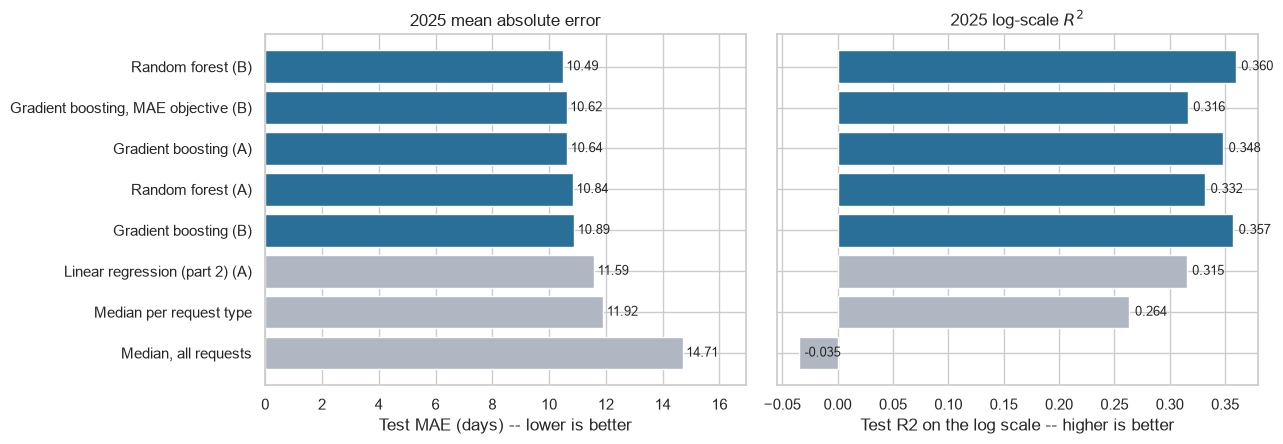

In [11]:
results = pd.DataFrame(rows)
results.to_csv(RESULTS_DIR / "model_comparison.csv", index=False)

print("2025 test set, scored once")
display(results.round(3))

order = results.sort_values("MAE")
labels = [f"{r.model}" + (f" ({r.features})" if r.features != "--" else "")
          for r in order.itertuples()]
colors = ["#b0b7c3" if r.model.startswith(("Median", "Linear")) else "#2a6f97"
          for r in order.itertuples()]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
axes[0].barh(labels, order["MAE"], color=colors)
axes[0].invert_yaxis()
axes[0].set_xlabel("Test MAE (days) -- lower is better")
axes[0].set_title("2025 mean absolute error")
axes[0].set_xlim(0, max(order["MAE"]) * 1.15)
for i, v in enumerate(order["MAE"]):
    axes[0].text(v + 0.12, i, f"{v:.2f}", va="center", fontsize=9)

axes[1].barh(labels, order["R2_log"], color=colors)
axes[1].invert_yaxis()
axes[1].set_xlabel("Test R2 on the log scale -- higher is better")
axes[1].set_title("2025 log-scale $R^2$")
for i, v in enumerate(order["R2_log"]):
    axes[1].text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=9)
axes[1].set_yticklabels([])
savefig("16_model_comparison")

Three things come out of this table.

**Both tree models beat the linear regression, and the gap is real.** The best forest cuts test MAE
from 11.59 days to 10.49, about 1.1 days per request, and lifts log-scale R² from 0.315 to 0.360.
That is the first clear improvement over "predict this request type's median" the project has had:
part 2's linear model beat that rule by 0.33 days, while the forest beats it by 1.43.

**The expanded feature set helps the forest and hurts boosting.** Set B improves the forest
(10.84 → 10.49) and costs boosting (10.64 → 10.89). Set B adds seven columns at once, so this table
cannot say which column is responsible, nor whether the boosting result is about the features
themselves or about how LightGBM encodes them. Section 8 adds them one at a time, and the answer is
not the one we expected when we built the set.

**R² in days stays low for every model.** It never clears 0.17. This is the same long-tail effect
part 2 described: squared error in days is dominated by the minority of requests that take months,
and no model here predicts those. MAE remains the honest headline, and it is still around ten days.

A note on the `R2_log` column for the two median rules. Their day-scale MAE, RMSE and R² match part 2
exactly. Their log-scale R² does not, and should not: part 2's log-scale table scored the *mean log
time* of each request type (0.301), whereas the row here is the *median days* of each type converted
to the log scale (0.264). Both are correct; they are different predictors, and the mean-log version
is the stronger one on a log-scale metric by construction.

## 8. Which of the new features actually did the work?

Set B added seven columns at once, and the forest improved while boosting did not. Adding them one
at a time shows which column carries the gain, and whether the boosting result is a property of the
features or of how LightGBM treats them.

Each boosting variant is tuned by the same early stopping on the same validation quarter, then refit
on 2024 and scored on 2025. The forest reuses one fixed setting throughout, rather than being
retuned per variant: the point here is to isolate the effect of *adding a column*, which a changing
hyperparameter would confound.

In [12]:
VARIANTS = {
    "A (part 2's set)": [],
    "+ Agency": ["Agency"],
    "+ MethodReceived": ["MethodReceived"],
    "+ Latitude/Longitude": ["Latitude", "Longitude", "has_valid_coords"],
    "+ CouncilDistrict": ["CouncilDistrict"],
    "+ Neighborhood": ["Neighborhood"],
    "B (all of the above)": CATS_B[4:] + NUMS_B[1:],
}
base_cols = CATS_A + NUMS_A
inc_rows = []

for name, extra in VARIANTS.items():
    cols = base_cols + list(extra)
    cats = [c for c in cols if c in CATS_B]

    # LightGBM, early stopped on the validation quarter.
    m = lgb.LGBMRegressor(**LGB_BASE, num_leaves=127, min_child_samples=100)
    m.fit(tr_in[cols], y["tr_in"], eval_set=[(val[cols], y["val"])], eval_metric="l2",
          categorical_feature=cats, callbacks=[lgb.early_stopping(100, verbose=False)])
    n_rounds = m.best_iteration_
    f = lgb.LGBMRegressor(**{**LGB_BASE, "n_estimators": n_rounds},
                          num_leaves=127, min_child_samples=100)
    f.fit(train[cols], y["train"], categorical_feature=cats)

    # Random forest, with the tuned setting from section 5 and codes for the categoricals.
    def codes(frame):
        X = frame[cols].copy()
        for c in cats:
            X[c] = X[c].cat.codes.astype(np.int32)
        return X

    rf = RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=SEED, **rf_best["B"])
    rf.fit(codes(train), y["train"])

    inc_rows.append({
        "features": name,
        "GB rounds": n_rounds,
        "GB valid MAE": metrics(d["val"], y["val"], m.predict(val[cols]))["MAE"],
        "GB test MAE": metrics(d["test"], y["test"], f.predict(test[cols]))["MAE"],
        "RF test MAE": metrics(d["test"], y["test"], rf.predict(codes(test)))["MAE"],
    })
    print(f"{name:24s} GB valid {inc_rows[-1]['GB valid MAE']:.3f}  "
          f"GB test {inc_rows[-1]['GB test MAE']:.3f}   "
          f"RF test {inc_rows[-1]['RF test MAE']:.3f}", flush=True)

incremental = pd.DataFrame(inc_rows)
incremental.to_csv(RESULTS_DIR / "incremental_features.csv", index=False)
display(incremental.round(3))

A (part 2's set)         GB valid 8.176  GB test 10.641   RF test 10.783


+ Agency                 GB valid 8.171  GB test 10.580   RF test 10.464


+ MethodReceived         GB valid 8.187  GB test 10.542   RF test 10.529


+ Latitude/Longitude     GB valid 8.135  GB test 10.674   RF test 10.623


+ CouncilDistrict        GB valid 8.164  GB test 10.723   RF test 10.646


+ Neighborhood           GB valid 8.164  GB test 10.857   RF test 10.650


B (all of the above)     GB valid 8.145  GB test 10.793   RF test 10.525


,features,GB rounds,GB valid MAE,GB test MAE,RF test MAE
0,A (part 2's set),97,8.1760,10.6410,10.7830
1,+ Agency,117,8.1710,10.5800,10.4640
2,+ MethodReceived,148,8.1870,10.5420,10.5290
3,+ Latitude/Longitude,108,8.1350,10.6740,10.6230
4,+ CouncilDistrict,102,8.1640,10.7230,10.6460
5,+ Neighborhood,91,8.1640,10.8570,10.6500
6,B (all of the above),86,8.1450,10.7930,10.5250


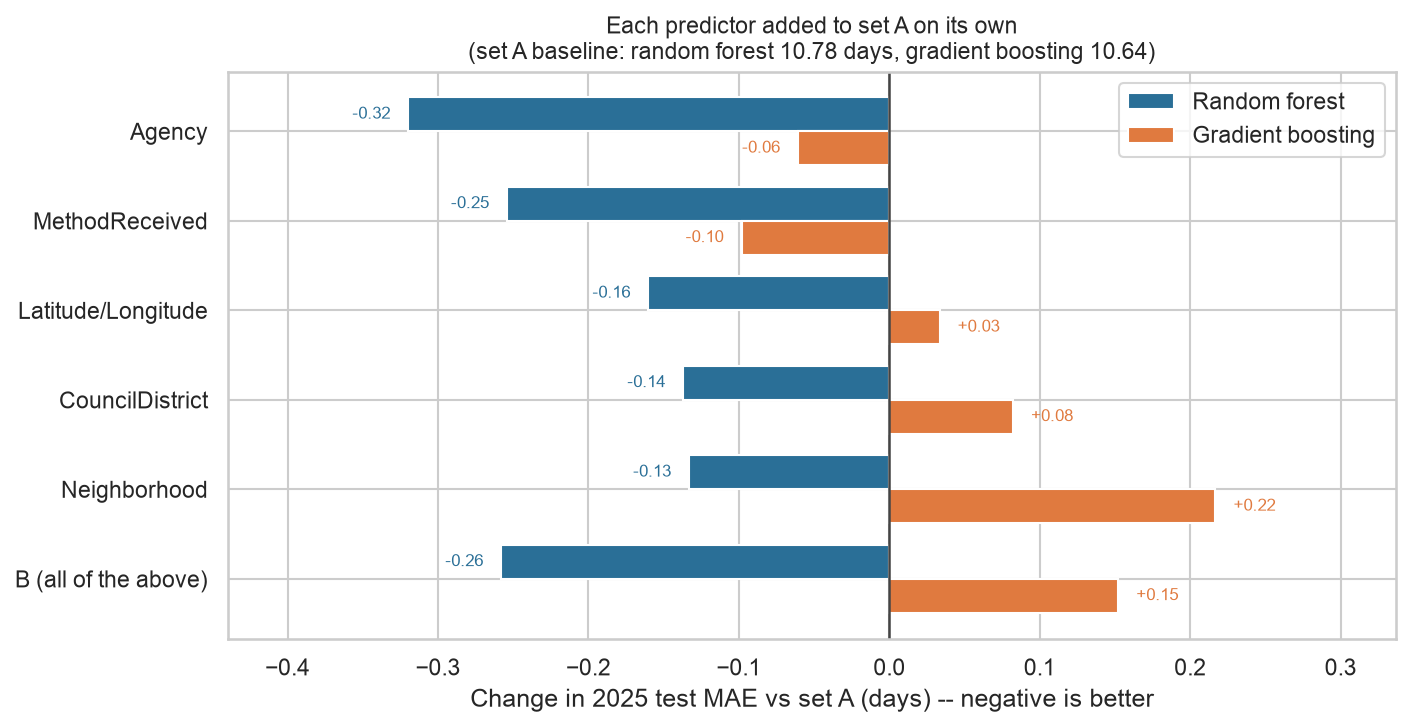

In [13]:
# Each bar is set A plus that one column -- the variants are alternatives, not a running total.
base_rf = incremental.loc[0, "RF test MAE"]
base_gb = incremental.loc[0, "GB test MAE"]
delta = incremental.iloc[1:].copy()
delta["RF"] = delta["RF test MAE"] - base_rf
delta["GB"] = delta["GB test MAE"] - base_gb
delta["label"] = delta["features"].str.replace("^\\+ ", "", regex=True)
delta = delta.iloc[::-1]

fig, ax = plt.subplots(figsize=(9.5, 5))
ypos = np.arange(len(delta))
h = 0.38
ax.barh(ypos + h / 2, delta["RF"], height=h, color="#2a6f97", label="Random forest")
ax.barh(ypos - h / 2, delta["GB"], height=h, color="#e07a3f", label="Gradient boosting")
ax.axvline(0, color="#444", linewidth=1.2)
ax.set_yticks(ypos)
ax.set_yticklabels(delta["label"])
ax.set_xlabel("Change in 2025 test MAE vs set A (days) -- negative is better")
ax.set_title("Each predictor added to set A on its own\n"
             f"(set A baseline: random forest {base_rf:.2f} days, gradient boosting {base_gb:.2f})",
             fontsize=11)
ax.legend(loc="upper right")
for yy, v in zip(ypos + h / 2, delta["RF"]):
    ax.text(v + (0.012 if v >= 0 else -0.012), yy, f"{v:+.2f}",
            va="center", ha="left" if v >= 0 else "right", fontsize=8, color="#2a6f97")
for yy, v in zip(ypos - h / 2, delta["GB"]):
    ax.text(v + (0.012 if v >= 0 else -0.012), yy, f"{v:+.2f}",
            va="center", ha="left" if v >= 0 else "right", fontsize=8, color="#e07a3f")
ax.set_xlim(min(delta[["RF", "GB"]].min()) - 0.12, max(delta[["RF", "GB"]].max()) + 0.12)
savefig("17_incremental_features")

This table overturns the reading we expected, in three ways.

**Agency is the most valuable addition, and it is not a location column.** It takes the forest from
10.78 to 10.46 days — a bigger gain than all seven columns together achieve (10.53). Intake method
is second. The two columns part 2 dismissed in a sentence each are the two that matter most.

That is a direct reversal of part 2's reasoning, and the reason is instructive. Part 2 excluded
agency because it is nearly collinear with request type: almost every type belongs to a single
agency, and the deadline's VIF was 10.6. All of that is true, and for a linear model it is
disqualifying — two collinear blocks split one effect between them and the coefficients stop meaning
anything individually. **A tree has no coefficients to corrupt.** It can use agency as a second
route to the same grouping, and that is worth a lot to a forest that otherwise reads request type
only through arbitrary integer codes: a clean 16-level column captures much of the same structure in
a form a single split can actually use. Collinearity is a problem for *interpretation*, not for
prediction, and part 2's exclusion rule imported a linear-model concern into a setting where it does
not apply.

**The location columns add far less than the set A → set B comparison implied.** Neighborhood,
council district and coordinates each buy the forest only 0.13 to 0.16 days, and each costs boosting
between 0.03 and 0.22. So the answer to "does location matter once a model can use it
non-additively" is a qualified yes that is much weaker than section 7 suggested — part 2 gave up
very little by leaving neighborhood out. The column it should not have dropped was agency.

**Adding everything is worse than adding the best thing.** For the forest, agency alone (10.46)
edges out all of set B (10.53), so the geography columns are slightly counterproductive on net even
for the model they help individually. The gap is small enough to be within run-to-run noise — note
that set B scores 10.53 here against 10.49 in the main table, from nothing but a different column
ordering changing which features `max_features=0.5` samples at each split. Differences below about
0.05 days in this notebook should not be read as real.

**Validation barely registers any of it.** The boosting validation column spans 0.05 days across
every variant while its test column swings 0.32, and validation's favourite (`+ Latitude/Longitude`,
8.135) is a change that makes the test year *worse* (10.674 against 10.641). The same thing happened
in section 5: the setting validation chose for set A, `max_features='sqrt', min_samples_leaf=5`,
scores 10.84 on 2025, while the setting it chose for set B scores 10.78 on that same feature set.
Something is systematically wrong with validating inside the training year, and the next cell pins
down what.

The obvious explanation for the boosting result is that it overfits a 280-level column, which would
make the obvious fix more regularization of the categorical splits. `cat_smooth` and `cat_l2` shrink
the statistics LightGBM uses to group levels and `min_data_per_group` refuses to split out small
ones. The cell below tries that, and the failure is worth more than the fix would have been.

In [14]:
REG_TRIALS = {
    "default": {},
    "cat_smooth=200, cat_l2=25": {"cat_smooth": 200, "cat_l2": 25},
    "cat_smooth=500, cat_l2=50, min_group=500": {"cat_smooth": 500, "cat_l2": 50,
                                                 "min_data_per_group": 500},
}
reg_rows = []
cols_B = CATS_B + NUMS_B
for rname, reg in REG_TRIALS.items():
    m = lgb.LGBMRegressor(**LGB_BASE, num_leaves=127, min_child_samples=100, **reg)
    m.fit(tr_in[cols_B], y["tr_in"], eval_set=[(val[cols_B], y["val"])], eval_metric="l2",
          categorical_feature=CATS_B, callbacks=[lgb.early_stopping(100, verbose=False)])
    n_rounds = m.best_iteration_
    f = lgb.LGBMRegressor(**{**LGB_BASE, "n_estimators": n_rounds},
                          num_leaves=127, min_child_samples=100, **reg)
    f.fit(train[cols_B], y["train"], categorical_feature=CATS_B)
    reg_rows.append({
        "categorical regularization": rname,
        "rounds": n_rounds,
        "valid MAE (Oct-Dec 2024)": metrics(d["val"], y["val"], m.predict(val[cols_B]))["MAE"],
        "test MAE (2025)": metrics(d["test"], y["test"], f.predict(test[cols_B]))["MAE"],
    })
    print(f"{rname:42s} valid {reg_rows[-1]['valid MAE (Oct-Dec 2024)']:.3f}  "
          f"test {reg_rows[-1]['test MAE (2025)']:.3f}", flush=True)

reg_df = pd.DataFrame(reg_rows)
reg_df.to_csv(RESULTS_DIR / "categorical_regularization.csv", index=False)
display(reg_df.round(3))
print(f"Validation picks: {reg_df.loc[reg_df['valid MAE (Oct-Dec 2024)'].idxmin(), 'categorical regularization']}")
print(f"Test prefers:    {reg_df.loc[reg_df['test MAE (2025)'].idxmin(), 'categorical regularization']}")

default                                    valid 8.145  test 10.793


cat_smooth=200, cat_l2=25                  valid 8.101  test 10.861


cat_smooth=500, cat_l2=50, min_group=500   valid 8.167  test 10.907


,categorical regularization,rounds,valid MAE (Oct-Dec 2024),test MAE (2025)
0,default,86,8.1450,10.7930
1,"cat_smooth=200, cat_l2=25",103,8.1010,10.8610
2,"cat_smooth=500, cat_l2=50, min_group=500",121,8.1670,10.9070


Validation picks: cat_smooth=200, cat_l2=25
Test prefers:    default


Regularizing the categorical splits does not help. Test MAE gets monotonically worse as the
regularization strengthens, and the two columns rank the three settings differently: validation
prefers `cat_smooth=200`, while the test year prefers the plain default and places `cat_smooth=200`
behind it.

That rules out the overfitting story in its simple form. If the model were merely carving out
neighborhood groups too small to be reliable, holding those groups together would have helped on
both columns. Instead, the fine-grained neighborhood structure LightGBM finds is *genuinely there in
2024* — which is why October–December 2024 endorses it — and it **does not hold in 2025**.

This is the most important methodological result in the notebook, and it is a warning about our own
validation design. A validation set drawn from inside the training year cannot see the thing that
breaks: it measures how well a pattern generalizes across months, while the test set measures how
well it generalizes across years. Those came apart here. Any hyperparameter chosen on
October–December 2024 is chosen for the wrong target, which is why section 12 proposes validating
across a year boundary instead.

It also explains the asymmetry with the forest. The forest reads neighborhood through integer codes,
which is a blunt instrument: a split can only cut the arbitrary code ordering, so the forest picks up
broad geographic contrasts and cannot isolate individual neighborhoods. Here that bluntness is an
accidental virtue. The coarse signal transfers to 2025; the fine detail does not. The better encoding
lost to the worse one because the worse one could not represent what failed to generalize.

## 9. What the models rely on

Three importance measures, because they disagree and the disagreement is informative.

- **Forest impurity importance** — total variance reduction credited to each column. It is the
  cheapest and the most misleading: it inflates columns with many distinct values, because a column
  with more possible cut points gets more chances to look good. `sla_days` (113,995 distinct values)
  and the integer-coded categoricals are exactly the columns that benefit.
- **LightGBM gain** — the same idea on the boosted ensemble, with the same cardinality caveat.
- **Permutation importance** — shuffle one column in the test data and measure how much worse
  predictions get. It is the one that answers "what does the model actually depend on at
  prediction time," it is measured on held-out data, and it is not fooled by cardinality. It is also
  the only one of the three that can be distorted by correlated columns, which matters here because
  the geography columns overlap.

In [15]:
rf_imp = pd.Series(rf_models["B"].feature_importances_,
                   index=make_X(train, "B", "codes").columns)
gain = pd.Series(lgb_models["B"].booster_.feature_importance("gain"),
                 index=make_X(train, "B", "category").columns)

perm_n = 60_000
perm_idx = np.random.default_rng(SEED).choice(len(test), perm_n, replace=False)
t = time.time()
perm = permutation_importance(
    rf_models["B"], make_X(test, "B", "codes").iloc[perm_idx], y["test"][perm_idx],
    scoring="neg_mean_absolute_error", n_repeats=3, random_state=SEED, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=make_X(train, "B", "codes").columns)
print(f"Permutation importance on {perm_n:,} test rows in {time.time() - t:.0f}s")

imp = pd.DataFrame({
    "RF impurity %": (rf_imp / rf_imp.sum() * 100),
    "GB gain %": (gain / gain.sum() * 100),
    "RF permutation (log-MAE)": perm_imp,
}).sort_values("RF permutation (log-MAE)", ascending=False)
display(imp.round(3))

Permutation importance on 60,000 test rows in 22s


,RF impurity %,GB gain %,RF permutation (log-MAE)
sla_days,42.3110,3.5460,0.5280
request_type,26.4780,83.1660,0.2150
Agency,9.4600,1.0490,0.0720
Latitude,4.1810,0.1660,0.0210
Longitude,4.7470,0.3980,0.0200
MethodReceived,1.4020,0.1170,0.0180
created_hour,1.7780,0.7110,0.0150
created_month,4.4660,2.6910,0.0110
created_dayofweek,1.4350,0.5950,0.0110
Neighborhood,2.3280,7.4590,0.0100


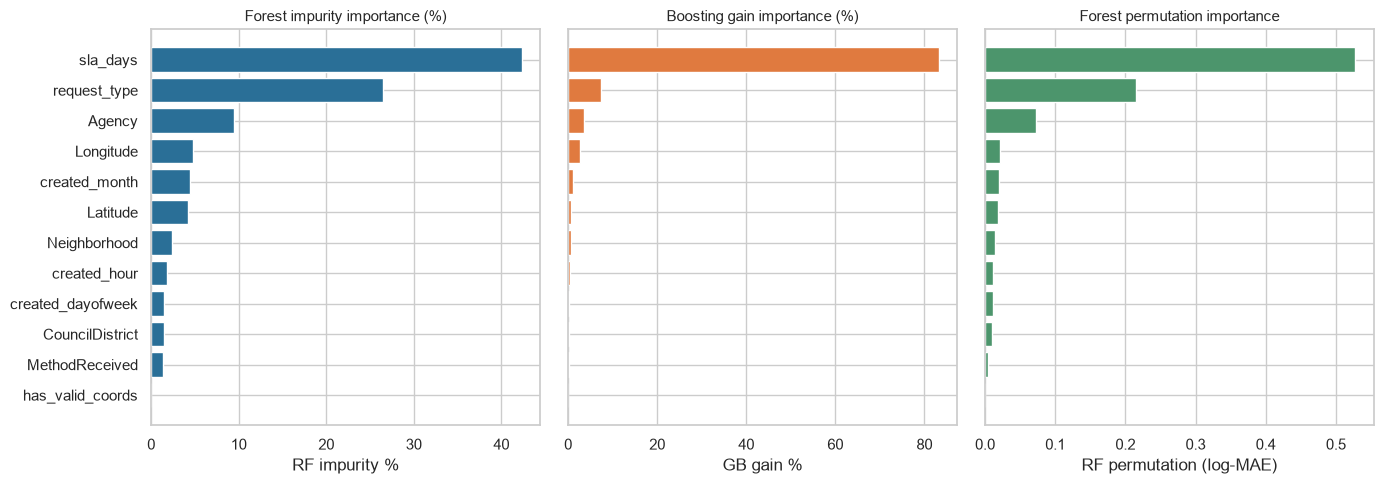

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
panels = [
    ("RF impurity %", "#2a6f97", "Forest impurity importance (%)"),
    ("GB gain %", "#e07a3f", "Boosting gain importance (%)"),
    ("RF permutation (log-MAE)", "#4c956c", "Forest permutation importance"),
]
for ax, (col, color, title) in zip(axes, panels):
    s = imp[col].sort_values()
    ax.barh(s.index, s.values, color=color)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel(col)
for ax in axes[1:]:
    ax.set_yticklabels([])
savefig("18_feature_importance")

The forest and the boosted model describe themselves completely differently, and the disagreement is
not an artifact.

**The forest leans on the deadline; boosting leans on request type.** Permutation importance — the
measure that is actually held out and actually about prediction — puts `sla_days` first for the
forest by more than a factor of two over request type (0.53 against 0.22 log-days of MAE). Boosting
credits request type with 83% of its gain and the deadline with 3.5%.

The cardinality caveat does not explain this away. We expected impurity importance to inflate
`sla_days`, which has 113,995 distinct values and therefore far more candidate split points than any
other column, and it does: 42% against request type's 26%. But permutation importance is not
vulnerable to that, and it agrees. The forest really does depend on the deadline most.

**The explanation is part 2's collinearity finding, read forwards.** Part 2 established that about
91% of the deadline's variation is request type — the deadline is largely a label for the kind of
work. For the forest, that makes `sla_days` a *numeric proxy for request type*, and a far more
usable one than request type itself: the forest sees request type only as arbitrary integer codes
that a split can merely cut, whereas the deadline encodes much of the same grouping on a real
number line that a single threshold can exploit. Shuffling `sla_days` destroys the forest's main
handle on what kind of request it is looking at. LightGBM, which can group categorical levels
natively, has no need for the proxy and uses the column itself.

This is the same mechanism that made agency so valuable in section 8, and it is the clearest
practical consequence of the encoding limitation flagged in section 3. It also means the three
importance columns should not be averaged or treated as competing estimates of one quantity: they
are answers to different questions about two models that solved the problem differently.

**Neighborhood is where the two measures disagree most sharply.** Boosting gives it 7.5% of gain,
second only to request type; the forest's permutation importance puts it tenth, at 0.010. That is
section 8's finding from the other direction — boosting invests heavily in neighborhood structure,
and that investment is what fails to carry into 2025.

## 10. SHAP

Importance says *how much* a column matters. SHAP says *which way* and *for which requests*: every
prediction is decomposed into one additive contribution per feature, on the log-days scale, and
those contributions sum exactly to the prediction minus the dataset average.

`TreeExplainer` is exact for tree ensembles, and it runs on the boosted model rather than the forest
because 300 deep trees are far more expensive to walk than ~100 shallow ones. The explanations below
therefore describe the gradient boosting model on set B, not the winning forest; the two agree on
the broad ordering.

SHAP on 4,000 test rows in 0s
Base value (average prediction): 1.620 log-days = 4.05 days

Share of total absolute SHAP contribution


,percent
request_type,61.3200
sla_days,16.6500
Neighborhood,7.6300
created_month,5.5400
created_dayofweek,2.7100
Agency,2.5000
created_hour,2.0300
MethodReceived,0.6200
Longitude,0.4500
CouncilDistrict,0.3200


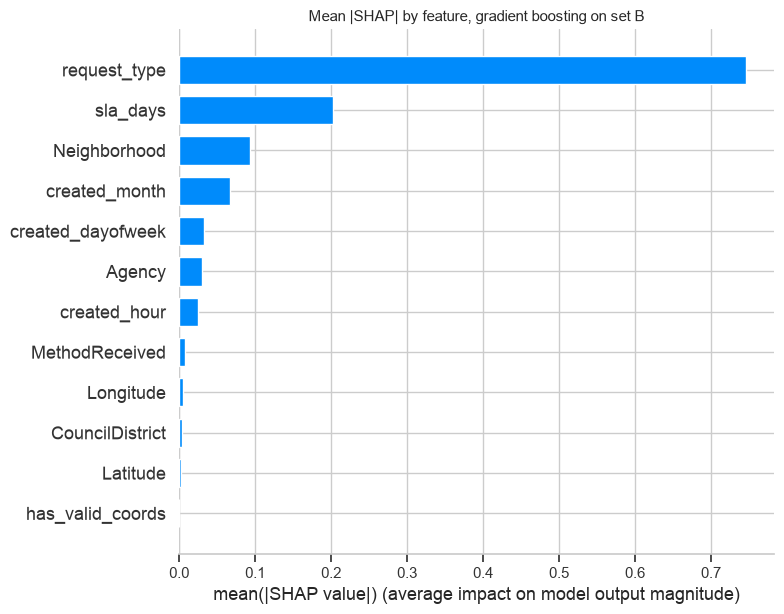

In [17]:
shap_n = 4_000
shap_idx = np.random.default_rng(SEED).choice(len(test), shap_n, replace=False)
X_shap = make_X(test, "B", "category").iloc[shap_idx]

t = time.time()
explainer = shap.TreeExplainer(lgb_models["B"])
shap_values = explainer.shap_values(X_shap)
print(f"SHAP on {shap_n:,} test rows in {time.time() - t:.0f}s")
print(f"Base value (average prediction): {explainer.expected_value:.3f} log-days "
      f"= {np.expm1(explainer.expected_value):.2f} days")

contrib = pd.Series(np.abs(shap_values).mean(axis=0), index=X_shap.columns)
contrib = (contrib / contrib.sum() * 100).sort_values(ascending=False)
print("\nShare of total absolute SHAP contribution")
display(contrib.round(2).to_frame("percent"))

plt.figure()
shap.summary_plot(shap_values, X_shap, plot_type="bar", show=False, max_display=12)
plt.title("Mean |SHAP| by feature, gradient boosting on set B", fontsize=11)
savefig("19_shap_importance")

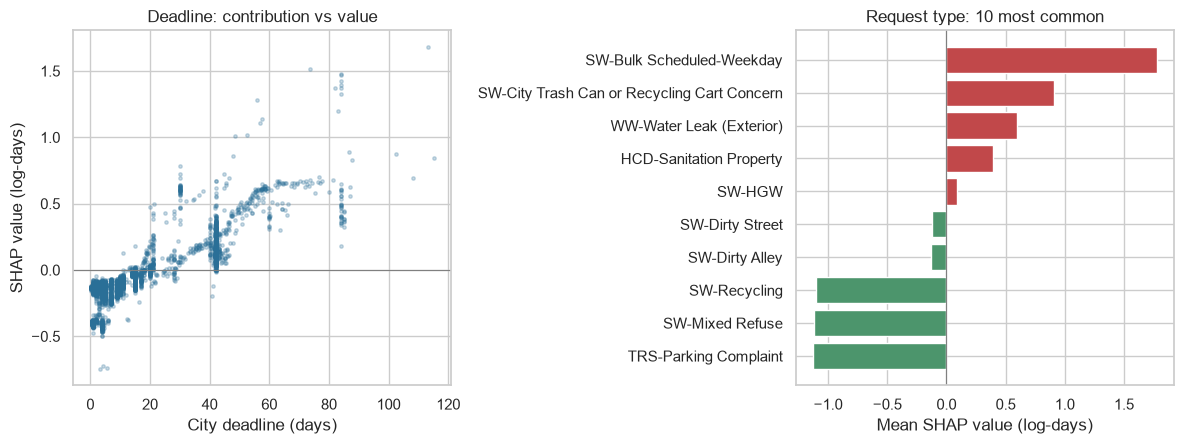

In [18]:
# Where does the deadline push a prediction? The one continuous feature worth a dependence plot.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
j = list(X_shap.columns).index("sla_days")
axes[0].scatter(X_shap["sla_days"], shap_values[:, j], s=6, alpha=0.25, color="#2a6f97")
axes[0].axhline(0, color="gray", linewidth=0.8)
axes[0].set_xlabel("City deadline (days)")
axes[0].set_ylabel("SHAP value (log-days)")
axes[0].set_title("Deadline: contribution vs value")

top_types = test["request_type"].value_counts().head(10).index
jt = list(X_shap.columns).index("request_type")
type_shap = (pd.DataFrame({"t": X_shap["request_type"].astype(str), "s": shap_values[:, jt]})
             .query("t in @top_types").groupby("t")["s"].mean().sort_values())
axes[1].barh(type_shap.index, type_shap.values,
             color=np.where(type_shap.values > 0, "#c1484a", "#4c956c"))
axes[1].axvline(0, color="gray", linewidth=0.8)
axes[1].set_xlabel("Mean SHAP value (log-days)")
axes[1].set_title("Request type: 10 most common")
savefig("20_shap_detail")

The base value is 1.62 log-days, or **4.05 days** — the average prediction, and the point every
decomposition starts from. Request type supplies 61% of all absolute contribution, the deadline 17%,
and neighborhood 7.6%; the ordering tracks LightGBM's gain importance, as it should, since both
describe the same model.

The deadline's dependence plot rises steadily (correlation 0.85 between the deadline and its own
contribution) and **crosses zero right around the three-week mark**. A deadline under 21 days
actively pushes a prediction *down* — by about 0.28 log-days for same-day deadlines — and a long
deadline pushes it up, reaching +0.63 past two months. This is part 2's positive within-type slope
seen per request instead of as one coefficient, and the vertical spread at any fixed deadline is the
interaction a single slope could not express: the same deadline means different things for different
kinds of work.

The request-type panel needs reading against the error analysis in section 11, because the two
together say something neither says alone. The three highest-volume types — parking complaints,
mixed refuse and recycling — all push predictions *down* by about 1.1 log-days, while scheduled bulk
pickup pushes up by 1.78 (it is genuinely scheduled work, which is why part 2 found its 42-day
deadline closing faster than the 30-day one).

Parking complaints are the instructive case. The model shifts them firmly toward "fast", and for the
typical parking complaint that is correct: the median closes in **0.46 days**. Yet they are also the
second-worst type in the error table, at 25.4 days of MAE with a bias of +25.3. Both facts hold at
once because the distribution is bimodal — most close within hours, a minority runs for months — and
a single-number prediction trained on squared log error lands near the median and therefore misses
the tail completely. The SHAP panel shows the model making a defensible choice; the error table shows
what that choice costs.

## 11. Where the model goes wrong

The research question asks whether performance differs across neighborhoods and request types, so
the error breakdown is a result in its own right, not a diagnostic afterthought. Both tables use the
best model by test MAE.

`bias` is mean actual minus mean predicted, in days. Positive means the model is **optimistic**:
those requests took longer than it said.

In [19]:
fitted = results[results.apply(lambda r: (r["model"], r["features"]) in preds, axis=1)]
best_row = fitted.loc[fitted["MAE"].idxmin()]
best_key = (best_row["model"], best_row["features"])
best_name = f"{best_row['model']} (set {best_row['features']})"
best_pred_log = preds[best_key]
best_pred_days = np.expm1(best_pred_log)
print(f"Best model: {best_name}, test MAE {best_row['MAE']:.3f} days")

err = pd.DataFrame({
    "request_type": test["request_type"].astype(str).to_numpy(),
    "Neighborhood": test["Neighborhood"].astype(str).to_numpy(),
    "actual": d["test"],
    "pred": best_pred_days,
})
err["abs_err"] = (err["actual"] - err["pred"]).abs()
err["signed"] = err["actual"] - err["pred"]

by_type = (err.groupby("request_type")
           .agg(n=("abs_err", "size"), MAE=("abs_err", "mean"),
                bias=("signed", "mean"), median_actual=("actual", "median"))
           .query("n >= 2000").sort_values("MAE", ascending=False))
print("\nHardest request types (at least 2,000 test requests)")
display(by_type.head(10).round(2))
print("Easiest request types")
display(by_type.tail(5).round(2))

by_hood = (err.groupby("Neighborhood")
           .agg(n=("abs_err", "size"), MAE=("abs_err", "mean"), bias=("signed", "mean"))
           .query("n >= 2000").sort_values("MAE", ascending=False))
print(f"\nNeighborhood MAE, {len(by_hood)} neighborhoods with at least 2,000 test requests")
display(pd.concat([by_hood.head(5), by_hood.tail(5)]).round(2))
by_type.to_csv(RESULTS_DIR / "error_by_request_type.csv")
by_hood.to_csv(RESULTS_DIR / "error_by_neighborhood.csv")

Best model: Random forest (set B), test MAE 10.489 days

Hardest request types (at least 2,000 test requests)


,n,MAE,bias,median_actual
request_type,,,,
TRT-Sign Damaged/Sign Structure,2691,72.2900,69.0600,34.1200
TRS-Parking Complaint,46179,25.3900,25.3200,0.4600
Other,8354,23.8700,17.9600,4.2600
WW-Water Leak (Exterior),11986,22.5000,15.6300,3.1600
FOR-Down Tree,2051,20.1400,12.9900,2.8500
ECC-Citizen Complaint or Concern,2329,17.5800,15.0000,3.7700
TRS-48 Hour Parking/Abandoned Vehicle,9189,14.5100,11.9800,12.7700
SW-City Trash Can or Recycling Cart Concern,14765,14.5000,9.4900,14.0800
BGE-StLight(s) Out,8431,14.1000,10.9000,1.2200


Easiest request types


,n,MAE,bias,median_actual
request_type,,,,
TRM-Snow/Icy Conditions,2829,0.7100,-0.0700,0.5800
SW-Recycling,17075,0.6900,0.6000,0.8400
HLTH-Animal In Danger/Injured/Abused/Neglected,5865,0.3600,0.0500,0.0800
SW-Public (Corner) Trash Can Issue,2236,0.2500,0.1200,0.7100
TRM-Pickup Pothole,5277,0.0000,-0.0000,0.0000



Neighborhood MAE, 73 neighborhoods with at least 2,000 test requests


,n,MAE,bias
Neighborhood,,,
Washington Village/Pigtown,5761,15.4200,13.2100
Riverside,3676,14.8500,12.1000
CARE,2124,13.6600,10.4700
Unknown,12429,12.9800,9.2800
Mount Clare,3143,12.6900,6.0800
Park Circle,2670,7.2000,3.8100
Edmondson Village,2264,7.0700,5.4000
Edgewood,2044,7.0100,4.2000
Upper Fells Point,3739,6.9500,4.5100


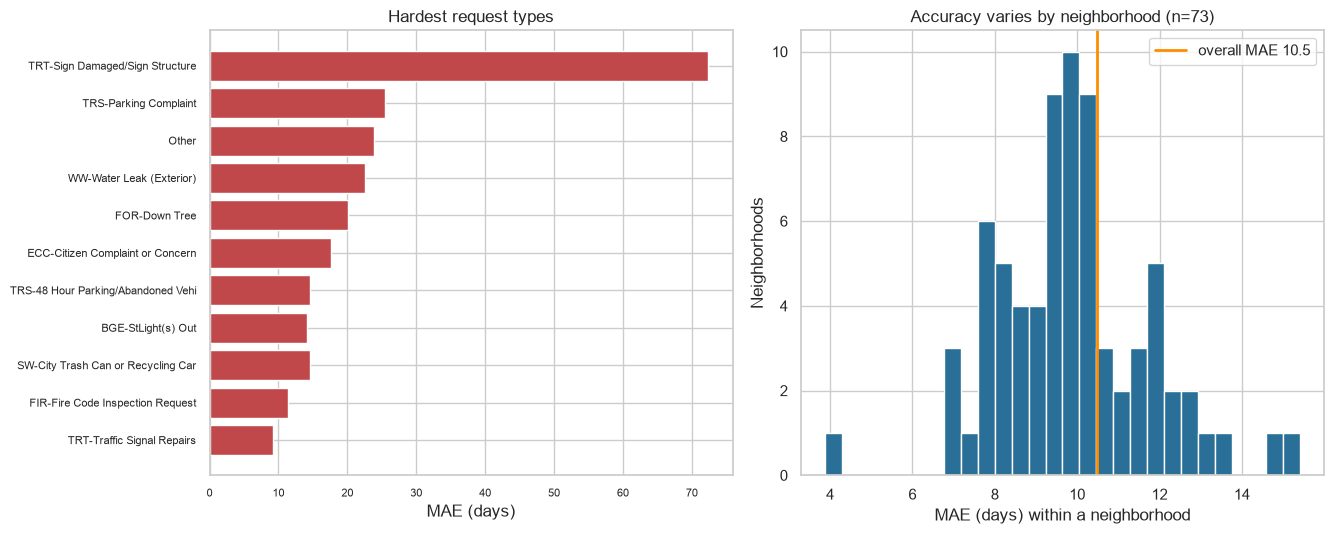

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.5))

top = by_type.head(12).iloc[::-1]
axes[0].barh(top.index.str.slice(0, 34), top["MAE"], color="#c1484a")
axes[0].set_xlabel("MAE (days)")
axes[0].set_title("Hardest request types")
axes[0].tick_params(labelsize=8)

axes[1].hist(by_hood["MAE"], bins=28, color="#2a6f97", edgecolor="white")
axes[1].axvline(best_row["MAE"], color="darkorange", linewidth=2,
                label=f"overall MAE {best_row['MAE']:.1f}")
axes[1].set_xlabel("MAE (days) within a neighborhood")
axes[1].set_ylabel("Neighborhoods")
axes[1].set_title(f"Accuracy varies by neighborhood (n={len(by_hood)})")
axes[1].legend()
savefig("21_error_breakdown")

The overall MAE of 10.5 days is an average over wildly unequal cases, and the inequality is the
result.

**Error is concentrated in a few request types, and the model is optimistic in almost all of them.**
Damaged-sign work is off by 72 days on average with a bias of +69: the model predicts a few days and
the median case actually takes 34. Parking complaints, at 46,179 test requests, are off by 25 days.
At the other end, pothole pickup has an MAE of **0.00 days** — the model is exactly right because
those requests close the moment they are filed. That is not skill. It is the administrative-closure
problem the cleaning notebook flagged as an open question in its "next steps", visible now as a
request type with zero resolution time, and it means some share of our headline accuracy comes from
predicting a clerical act rather than any city work.

**Bias is positive nearly everywhere.** Almost every hard type took longer than predicted, and no
type is badly pessimistic. A model trained on squared error in log space predicts something near the
conditional median, so it systematically under-calls the long right tail. That is a property of the
target and the loss, not a bug, but it does mean the model should not be described as estimating how
long a request will take. It estimates how long a *typical* request of that kind takes.

**Accuracy differs by a factor of four across neighborhoods.** Among the 73 neighborhoods with at
least 2,000 test requests, MAE runs from 3.9 days in Poppleton to 15.4 in Washington Village/Pigtown,
and the bias is positive in every one shown. This is a direct answer to the second half of the
research question — prediction performance is *not* uniform across the city — but it is not yet an
equity finding, and we should be careful not to present it as one. The spread could reflect the mix
of request types each neighborhood files rather than anything about the neighborhood itself, since
request type drives both the prediction and the error. Separating those two explanations needs the
error decomposed within request type, which is a specific and tractable task for the final phase.
One practical note: `Unknown` is the fourth-worst "neighborhood" with 12,429 test requests, and that
is an address-matching artifact, not a place.

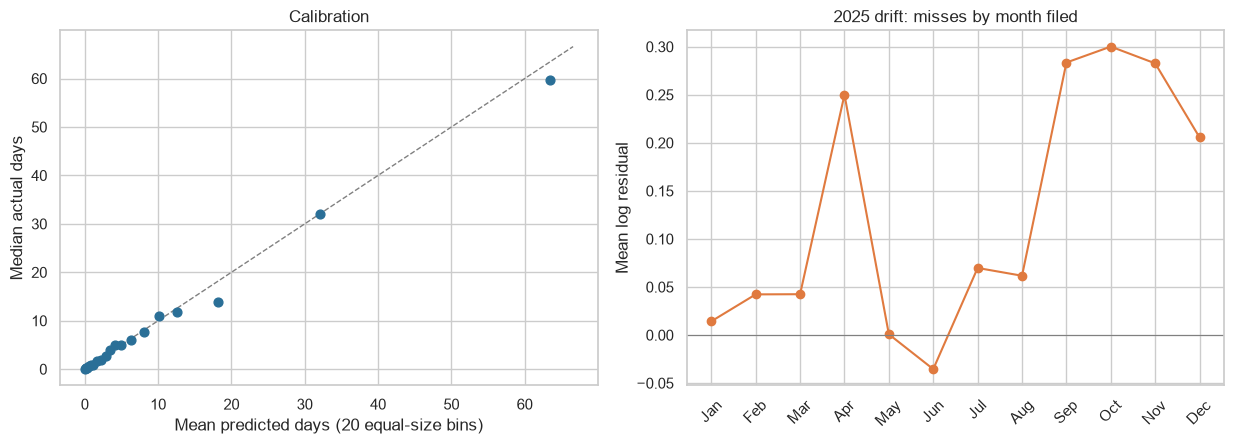

Mean log residual by 2025 month (positive = took longer than predicted)


month,1,2,3,4,5,6,7,8,9,10,11,12
mean_log_residual,0.0140,0.0420,0.0420,0.2500,0.0010,-0.0350,0.0700,0.0620,0.2840,0.3000,0.2830,0.2060


In [21]:
# Calibration: does the model track actual time across its own prediction range?
q = pd.qcut(err["pred"], 20, duplicates="drop")
cal = err.groupby(q, observed=True).agg(pred=("pred", "mean"), actual=("actual", "median"),
                                        n=("actual", "size"))
month_err = (pd.DataFrame({"month": test["month_num"].to_numpy(),
                           "resid_log": y["test"] - best_pred_log})
             .groupby("month")["resid_log"].mean())

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
lim = cal[["pred", "actual"]].to_numpy().max() * 1.05
axes[0].plot([0, lim], [0, lim], color="gray", linestyle="--", linewidth=1)
axes[0].scatter(cal["pred"], cal["actual"], s=40, color="#2a6f97", zorder=3)
axes[0].set_xlabel("Mean predicted days (20 equal-size bins)")
axes[0].set_ylabel("Median actual days")
axes[0].set_title("Calibration")

axes[1].plot(month_err.index, month_err.values, marker="o", color="#e07a3f")
axes[1].axhline(0, color="gray", linewidth=0.8)
axes[1].set_xticks(range(1, 13), MONTH_NAMES, rotation=45)
axes[1].set_ylabel("Mean log residual")
axes[1].set_title("2025 drift: misses by month filed")
savefig("22_calibration_and_drift")

print("Mean log residual by 2025 month (positive = took longer than predicted)")
display(month_err.round(3).to_frame("mean_log_residual").T)

## 12. Where this leaves the project

**What worked.** Both tree models beat part 2's linear regression on the 2025 test year. The random
forest on the expanded feature set is the best model so far at 10.49 days of MAE, against 11.59 for
the linear regression and 11.92 for predicting each request type's median. The improvement is
roughly a day per request, and it is the project's first clear win over the per-type median rule.

**The most useful thing we learned was not about model class.** We expected the gain to come from
location, since that is what part 2 had to leave out. It did not. Section 8 took the new columns one
at a time, and **agency** — a 16-level column part 2 excluded for being collinear with request
type — delivered more on its own (10.46) than all seven new columns together (10.53). The location
columns contributed 0.13 to 0.16 days each. The lesson generalizes beyond this project: part 2
excluded agency for a reason that is real for linear models and irrelevant for trees. Collinearity
corrupts coefficients, and a tree has none. We imported a diagnostic from one model class into
another where it does not apply, and it cost us the single best predictor available.

**What did not work.** Gradient boosting did not beat the forest, and the location columns actively
hurt it: neighborhood alone cost it 0.22 days. Regularizing the categorical splits, the obvious fix,
made it worse rather than better. Optimizing MAE directly with an L1 objective recovered most of
what set B had cost boosting (10.62 against 10.89) but still did not reach the forest. The forest
won in part *because* its encoding is cruder — reading a 280-level column as arbitrary integer codes,
it could only pick up broad geographic contrasts, and those were the ones that transferred.

**The methodological finding we did not expect, and the one worth presenting.** Our validation
design is broken, and the notebook caught it three separate times. Validation MAE on
October–December 2024 moved by 0.05 days across variants whose test MAE moved by 0.32; it preferred
the categorical regularization that test rejected; and the forest setting it chose for set A scored
worse on 2025 than the setting it chose for set B. A validation set drawn from inside the training
year measures generalization *across months*, while the test set measures generalization *across
years*, and in this data those are different problems. Any hyperparameter we tuned this way was
tuned against the wrong target.

**The obstacle that is still unsolved.** Every model is optimistic in the second half of 2025: mean
log residuals run +0.28 to +0.30 for September through November, against roughly zero in the first
half. Part 2 found this, no model class fixes it, and it is the same phenomenon that breaks the
validation design — a change in the city's behavior over time rather than a shortcoming of any fit.
This is the clearest target for the final phase.

**Plan for the final project.**

1. **Fix the validation design first**, because every other comparison depends on it. Use a rolling
   origin: tune on 2024 and validate on early 2025, or fit on successive windows and validate on the
   window that follows. Hyperparameter choice then faces the drift the test year actually contains.
   This is cheap, and section 8 shows the current scheme is actively misleading.
2. **Attack the drift directly.** Add features describing conditions at filing time rather than the
   calendar: the agency's open-request backlog, the recent median resolution time for that request
   type, days since the start of the series. A model that knows the system was already slow in
   October 2025 does not need to have seen October 2025.
3. **Settle the administrative-closure question.** Pothole pickup has an MAE of zero because those
   requests close on creation. The cleaning notebook raised this and it is still open. Until it is
   decided, part of our reported accuracy is predicting data entry rather than city work.
4. **Decompose the neighborhood error within request type.** The four-fold spread in accuracy across
   neighborhoods is currently confounded with which request types each neighborhood files. Separating
   those is what turns a measurement into the equity finding the research question asks for.
5. **Enrich with Census ACS data** joined on neighborhood, which replaces 280 opaque levels with
   interpretable quantities — and, given that fine-grained neighborhood identity is exactly what
   failed to transfer to 2025, may generalize where the raw column did not.
6. **Model the tail instead of ignoring it.** Every model under-calls slow requests because it
   targets the conditional median. Quantile regression, or predicting whether a request will exceed
   its deadline at all, would be more useful than a point estimate and would address the bias that
   runs through the whole error analysis.